[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/santialferez/FDLE/blob/main/S3_Sampling_RNN/S3_Sampling_RNN_STUDENT.ipynb)

# Sampling, Cross-Validation & Intro to RNNs

Foundations of Deep Learning for Engineering · UPC · Session 3

Estimate an expectation by sampling, test how much an accuracy depends on the split, and compare ways to classify a sequence.
Work in pairs. Predict an outcome before changing a 🎛️ knob, then explain what you observed.

## Outline

Run Part 0 first. Use the slide numbers to find the corresponding class material.

| Part | Clock | Steps | You report | Slides |
|:--|:--|:--|:--|:--|
| Part 0 · Set up | 12:00 to 12:10 | ▶ S3·0 |  | 2, 11 |
| Lab 1 · Sample, validate, debug | 12:40 to 13:20 | 🎛️ L1·1 · 🎛️ L1·2 · 🐛 L1·3 | rejection acceptance at your chosen dimension, CIFAR-10 fold mean and bootstrap interval, and sensor accuracy before and after the fix. | 5, 6, 7, 9, 10, 12 |
| Lab 2 · From word counts to recurrent models | 14:45 to 15:25 | 🎛️ L2·1 · ▶ L2·2a · ▶ L2·2b · ✏️ L2·3 · ★ L2·STAR | BoW accuracy, recurrent cell and validation accuracy, and your best challenge configuration with its training time. | 16, 17, 18, 19, 20, 21, 22, 24 |
| Summary | Close |  |  | 26 |

## Part 0 · Set up

*Slides: "activate T4 GPU" and "the fdle course library" (slides 2 and 11).*

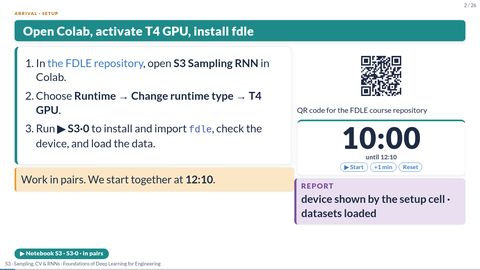 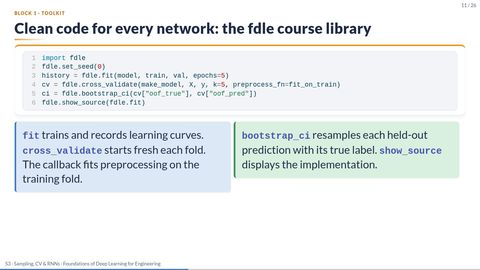

<sub>Slides 2 and 11 · activate T4 GPU | the fdle course library</sub>

In Colab, select a T4 GPU under **Runtime → Change runtime type**, then run the cell.
The first run downloads the data. FAST mode uses smaller subsets for quick checks.
The cell prints the source of `fdle.fit`; find the batch loop and the validation call.

In [ ]:
# ▶ S3·0
import os
import sys
import subprocess
import io
import json
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision.datasets import CIFAR10
from torchvision.models import ResNet18_Weights, resnet18

try:
    import fdle
except ModuleNotFoundError as error:
    if error.name != "fdle":
        raise
    local_fdle = os.environ.get("FDLE_LOCAL")
    if local_fdle:
        sys.path.insert(0, str(local_fdle))
    else:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q",
            "git+https://github.com/santialferez/FDLE.git",
        ])
    import fdle

FAST = os.environ.get("FAST") == "1"
DEVICE = fdle.get_device()
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Device: {DEVICE} · FAST={FAST}")
fdle.set_seed(0)

DATA = Path("./data")
DATA.mkdir(exist_ok=True)
RESULTS = fdle.ResultsTable()
REFERENCE = {}
HF_IMDB = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/"
HF_CIFAR = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/"
IMDB_SPLITS = [("train", 15_000, 0), ("test", 2_000, 1)]


def read_parquet(base, split, columns):
    url = base + f"{split}-00000-of-00001.parquet"
    response = requests.get(url, timeout=(5, 20))
    response.raise_for_status()
    return pd.read_parquet(io.BytesIO(response.content), columns=columns)


def sample_rows(labels, size, seed):
    """Take a reproducible sample that preserves the label proportions."""
    rows, _ = train_test_split(
        np.arange(len(labels)), train_size=size, stratify=labels, random_state=seed
    )
    return rows


def save_cache(path, **arrays):
    # Publish the cache only after all arrays have been written.
    with TemporaryDirectory(dir=path.parent) as folder:
        temporary = Path(folder) / path.name
        np.savez_compressed(temporary, **arrays)
        temporary.replace(path)


def synthetic_reviews(size, seed, split):
    rng = np.random.default_rng(seed)
    labels = rng.permutation(np.arange(size) % 2)
    verdicts = [
        ("dull", "tedious", "disappointing", "forgettable"),
        ("delightful", "absorbing", "excellent", "memorable"),
    ]
    genres = ["comedy", "drama", "thriller", "adventure"]
    reviews = [
        f"{split} review {i}. I watched this {rng.choice(genres)} last night. "
        f"The acting was {rng.choice(verdicts[y])} and the ending was "
        f"{rng.choice(verdicts[y if rng.random() < 0.85 else 1 - y])}."
        for i, y in enumerate(labels)
    ]
    return np.asarray(reviews), labels


def load_imdb():
    cache = DATA / "imdb_s3.npz"
    if cache.exists():
        with np.load(cache) as saved:
            arrays = {key: saved[key] for key in saved.files}
        if all(len(arrays[f"{split}_y"]) == size for split, size, _ in IMDB_SPLITS):
            return arrays, "IMDB cache"
        print("Refreshing the IMDB cache for the larger review subsets.")
    arrays = {}
    try:
        for split, size, seed in IMDB_SPLITS:
            frame = read_parquet(HF_IMDB, split, ["text", "label"])
            rows = sample_rows(frame["label"].to_numpy(), size, seed)
            texts = frame["text"].iloc[rows]
            arrays[f"{split}_text"] = texts.str.replace(r"<br\s*/?>", " ", regex=True).to_numpy(dtype=str)
            arrays[f"{split}_y"] = frame["label"].iloc[rows].to_numpy()
    except (requests.RequestException, ImportError, ValueError, OSError) as error:
        print(f"IMDB parquet unavailable ({error}). Using synthetic reviews for practice.")
        for split, size, seed in IMDB_SPLITS:
            arrays[f"{split}_text"], arrays[f"{split}_y"] = synthetic_reviews(size, seed, split)
        return arrays, "synthetic reviews"
    save_cache(cache, **arrays)
    return arrays, "Hugging Face IMDB"


def load_cifar():
    cache = DATA / "cifar10_s3.npz"
    if cache.exists():
        with np.load(cache) as saved:
            return saved["images"], saved["labels"]
    try:
        local = CIFAR10(DATA, train=False, download=False)
    except RuntimeError:
        # Each parquet image is a dictionary containing the original PNG bytes.
        frame = read_parquet(HF_CIFAR, "test", ["img", "label"])
        labels = frame["label"].to_numpy()
        rows = sample_rows(labels, 1000, 0)
        images = []
        for encoded in frame["img"].iloc[rows]:
            with Image.open(io.BytesIO(encoded["bytes"])) as image:
                images.append(np.asarray(image.convert("RGB")))
        images, labels = np.stack(images), labels[rows]
    else:
        labels = np.asarray(local.targets)
        rows = sample_rows(labels, 1000, 0)
        images, labels = local.data[rows], labels[rows]
    save_cache(cache, images=images, labels=labels)
    return images, labels


imdb, IMDB_SOURCE = load_imdb()
train_text, train_y = imdb["train_text"], imdb["train_y"]
val_text, val_y = imdb["test_text"], imdb["test_y"]
if FAST:
    train_rows = sample_rows(train_y, 400, 2)
    val_rows = sample_rows(val_y, 200, 3)
    train_text, train_y = train_text[train_rows], train_y[train_rows]
    val_text, val_y = val_text[val_rows], val_y[val_rows]
print(f"{IMDB_SOURCE}: {len(train_y):,} training / {len(val_y):,} validation reviews")
REFERENCE["imdb_source"] = IMDB_SOURCE

cifar_X = None
try:
    cifar_images, cifar_y = load_cifar()
except (requests.RequestException, ImportError, ValueError, OSError) as error:
    print(f"CIFAR-10 unavailable ({error}). Lab 1.2 will wait for access to the images.")
    cifar_images, cifar_y = None, None
else:
    if FAST:
        rows = sample_rows(cifar_y, 300, 1)
        cifar_images, cifar_y = cifar_images[rows], cifar_y[rows]
    print(f"CIFAR-10: {len(cifar_y):,} photos for resampling")
fdle.show_source(fdle.fit)

## Lab 1 · Sample, validate, debug

*Slide: "Lab 1" (slide 12).*

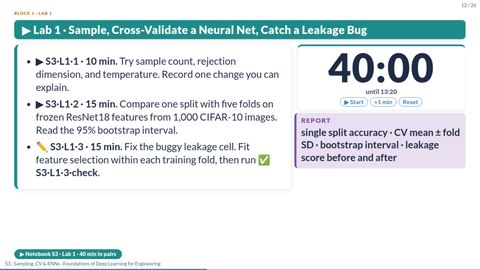

<sub>Slide 12 · Lab 1</sub>

40 minutes in pairs. Change the sampling knobs, compare a single split with five folds, then repair a validation bug.

**You report:** rejection acceptance at your chosen dimension, CIFAR-10 fold mean and bootstrap interval, and sensor accuracy before and after the fix.

### 🎛️ L1·1 · Three sampling knobs

*Slides: "Expectations by Monte Carlo" and "Inverse-CDF and Rejection" (slides 5 and 6), and "Importance sampling" (slide 7).*

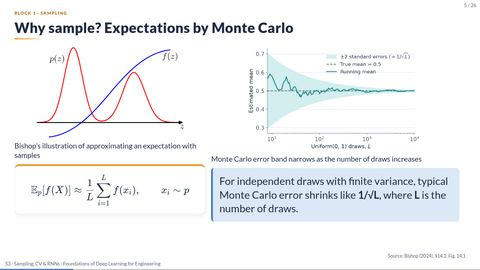 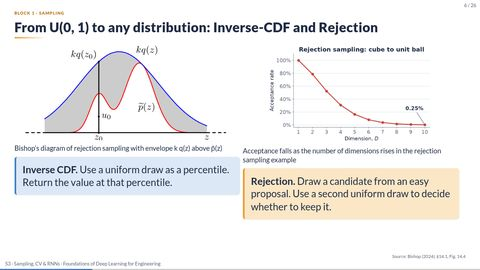 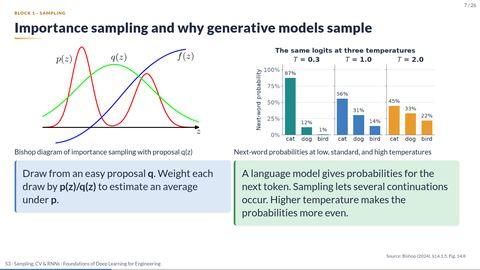

<sub>Slides 5 and 6 and 7 · Expectations by Monte Carlo | Inverse-CDF and Rejection | Importance sampling</sub>

- **Monte Carlo.** Estimate the mean of `U²` for `U` uniform on [0, 1]. The exact answer is 1/3. Increase **L**, the number of draws, and compare the errors across repeats.
- **Rejection.** Draw points uniformly from the cube [−1, 1]ᴰ. Accept a point if its distance from zero is at most 1. Try **D** = 2, 5 and 10. What happens to the fraction accepted?
- **Temperature.** Sample the next word from the same three scores. Try **TEMPERATURE** = 0.3, 1 and 2. Which setting produces the most varied samples?

In [ ]:
# ▶ S3·L1·1
L = 2_000         # try 200 or 20_000
D = 5             # try 2 or 10
TEMPERATURE = 1.0 # try 0.3 or 2.0

rng = np.random.default_rng(0)
draws = rng.uniform(size=(24, L))
checkpoints = np.unique(np.geomspace(1, L, num=35).astype(int))
estimates = np.cumsum(draws**2, axis=1)[:, checkpoints - 1] / checkpoints
rms_error = np.sqrt(((estimates - 1 / 3)**2).mean(axis=0))
plt.loglog(checkpoints, rms_error, label="Monte Carlo error across 24 repeats")
plt.loglog(checkpoints, np.sqrt(4 / (45 * checkpoints)), "--", label="1 / √L scaling")
plt.xlabel("Number of draws")
plt.ylabel("Root mean square error")
plt.legend()
plt.show()

points = rng.uniform(-1, 1, size=(20_000, D))
accepted = (points**2).sum(axis=1) <= 1
print(f"Rejection in {D} dimensions: {accepted.mean():.2%} accepted")

words = np.array(["coffee", "tea", "water"])
logits = torch.tensor([2.0, 1.0, 0.0])
prob = torch.softmax(logits / TEMPERATURE, dim=0).numpy()
counts = np.bincount(rng.choice(len(words), size=1_000, p=prob), minlength=len(words))
for word, p, count in zip(words, prob, counts):
    print(f"{word:7s} probability {p:5.1%} · {count:4d} draws")
REFERENCE["sampling"] = dict(L=L, D=D, temperature=TEMPERATURE,
                             acceptance=float(accepted.mean()), mc_error=float(rms_error[-1]))

✍️ **Why does rejection get harder as D increases?** *(double-click here and write)*

&nbsp;

### 🎛️ L1·2 · One split, five folds, and a bootstrap interval

*Slides: "Stratified K-Fold Cross-Validation" and "Data Leakage" (slides 9 and 10).*

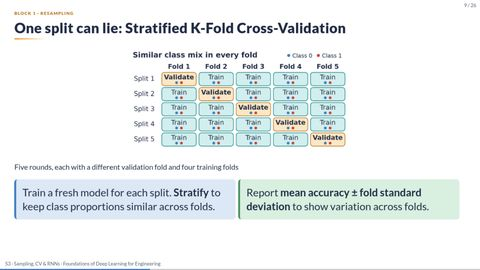 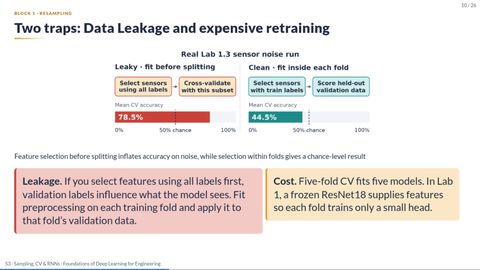

<sub>Slides 9 and 10 · Stratified K-Fold Cross-Validation | Data Leakage</sub>

A frozen ImageNet ResNet18 converts each photo into 512 features. Extract those once, then train a fresh two-layer MLP on four folds and score it on the fifth. Each photo gets one prediction from a head that never trained on it.

Change **SPLIT_SEED** and look for a lucky single split. The folds stay fixed. Their standard deviation describes how much accuracy varies across folds. The bootstrap resamples the existing out-of-fold predictions for a rough 95% interval, with no retraining. It does not capture all the uncertainty from fitting new models.

In [ ]:
# ▶ S3·L1·2
SPLIT_SEED = 7
HEAD_EPOCHS = 4 if FAST else 8
HEAD_LR = 0.003


@torch.inference_mode()
def frozen_features(images):
    weights = ResNet18_Weights.DEFAULT
    backbone = resnet18(weights=weights).to(DEVICE).eval()
    backbone.fc = nn.Identity()
    backbone.requires_grad_(False)
    # Use the pretrained normalization and a smaller 96 × 96 input for speed.
    transform = weights.transforms(crop_size=96, resize_size=96)
    features = []
    for batch in torch.from_numpy(images).permute(0, 3, 1, 2).split(64):
        batch = transform(batch.to(DEVICE))
        features.append(backbone(batch).cpu())
    return torch.cat(features)


def cifar_head():
    return nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Linear(64, 10))


if cifar_images is not None and cifar_X is None:
    try:
        cifar_X = frozen_features(cifar_images)
    except (OSError, RuntimeError) as error:
        print(f"Could not extract frozen features: {error}")

if cifar_X is not None:
    tr, va = train_test_split(
        np.arange(len(cifar_y)), test_size=0.2, stratify=cifar_y, random_state=SPLIT_SEED
    )
    cifar_labels = torch.as_tensor(cifar_y, dtype=torch.long)
    fdle.set_seed(0)
    single = fdle.fit(
        cifar_head(), (cifar_X[tr], cifar_labels[tr]), (cifar_X[va], cifar_labels[va]),
        epochs=HEAD_EPOCHS, lr=HEAD_LR, device=DEVICE, verbose=False,
    )
    single_acc = single["val_acc"][-1]
    cv = fdle.cross_validate(
        cifar_head, cifar_X, cifar_labels, k=5, epochs=HEAD_EPOCHS, lr=HEAD_LR, device=DEVICE
    )
    ci = fdle.bootstrap_ci(cv["oof_true"], cv["oof_pred"], n_boot=500)
    print(f"Single split: {single_acc:.1%}")
    print(f"Five folds: {cv['mean_acc']:.1%} ± {100 * cv['std_acc']:.1f} percentage points")
    print(f"95% bootstrap interval: {ci['low']:.1%} to {ci['high']:.1%}")
    fdle.plot_cv_scores(cv["fold_accs"], single_split_acc=single_acc, title="Frozen ResNet18 + MLP")
    plt.show()
    REFERENCE["cifar10"] = dict(single=single_acc, folds=cv["fold_accs"], mean=cv["mean_acc"],
                                std=cv["std_acc"], bootstrap_95=[ci["low"], ci["high"]])
else:
    print("CIFAR-10 and pretrained ResNet18 weights are needed for this comparison.")

### 🐛 L1·3 · Debug the data leakage

*Slide: "Data Leakage" (slide 10).*

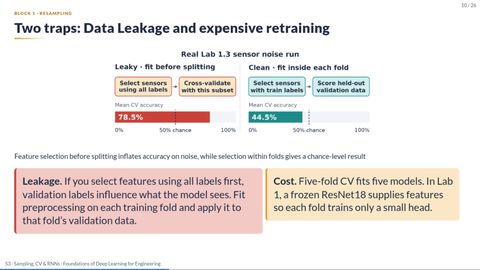

<sub>Slide 10 · Data Leakage</sub>

You have 200 parts, each measured by 1,000 sensors. The labels are balanced and assigned independently of the sensors. A colleague keeps the 20 sensors most correlated with the labels, then runs five-fold CV. Why does the model appear to work?

1. Run the cell and record its score.
2. Trace which labels `top_sensors` sees. Use the `fdle.cross_validate` hook with signature `preprocess_fn(X_train, y_train, X_val) -> (X_train_new, X_val_new)`.
3. Run the check. Explain how the held-out labels could affect the earlier score.

In [ ]:
# 🐛 S3·L1·3
rng = np.random.default_rng(42)
sensor_X = rng.normal(size=(200, 1000)).astype(np.float32)
sensor_y = rng.permutation(np.arange(200) % 2)


def top_sensors(X, y):
    # Rank columns by absolute Pearson correlation with the labels.
    centered = X - X.mean(axis=0)
    correlation = np.abs(centered.T @ (y - y.mean())) / centered.std(axis=0)
    return np.argsort(correlation)[-20:]


def sensor_head():
    return nn.Linear(20, 2)

keep = top_sensors(sensor_X, sensor_y)
res = fdle.cross_validate(
    sensor_head, sensor_X[:, keep], sensor_y,
    k=5, epochs=12, lr=0.03, device=DEVICE, verbose=False,
)
print(f"Mean accuracy: {res['mean_acc']:.1%}")

In [ ]:
# ▶ S3·L1·3·check
if 0.35 <= res["mean_acc"] <= 0.65:
    print(f"✅ Mean accuracy {res['mean_acc']:.1%} is near chance.")
    REFERENCE["clean_sensor_acc"] = res["mean_acc"]
else:
    print(f"❌ Mean accuracy {res['mean_acc']:.1%} is outside the expected 35% to 65% range.")
    print("Which labels are visible when you choose the 20 columns?")

✍️ **Which information leaked across the fold boundary?** *(double-click here and write)*

&nbsp;

## Lab 2 · From word counts to recurrent models

*Slide: "Lab 2" (slide 24).*

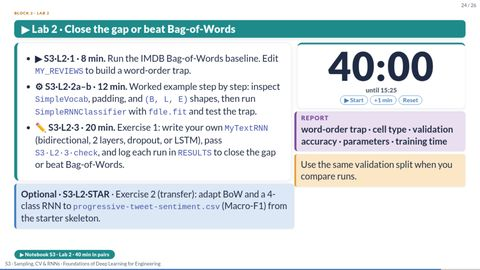

<sub>Slide 24 · Lab 2</sub>

40 minutes in pairs. Start with word counts, compare recurrent cells, then spend the last 15 minutes on your own IMDB experiment. All models use the same 15,000 training and 2,000 validation reviews (400 and 200 in FAST mode). The official IMDB test shard supplies the validation subset for this lab, so these scores serve classroom comparisons.

**You report:** BoW accuracy, recurrent cell and validation accuracy, and your best challenge configuration with its training time.

### 🎛️ L2·1 · Fool Bag-of-Words

*Slides: "Bag-of-Words forgets word order" (slide 16), "dense Word Embeddings" and "Fast Row Lookup" (slides 17 and 18).*

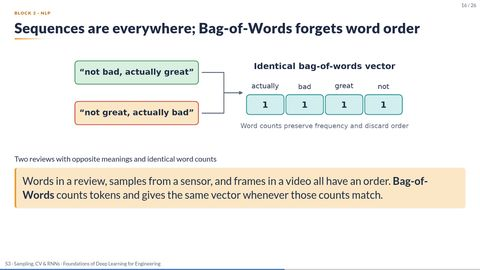 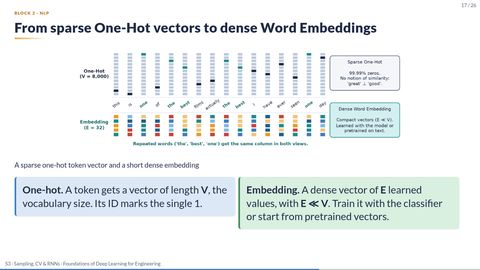 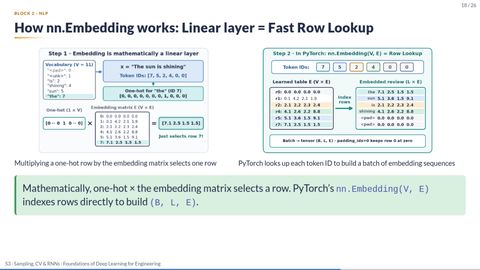

<sub>Slides 16 and 17 and 18 · Bag-of-Words forgets word order | dense Word Embeddings | Fast Row Lookup</sub>

Count words in each review and fit logistic regression. The vectorizer learns its vocabulary from the training reviews. Predict both examples in **MY_REVIEWS**, then write a pair with the same words in a different order and opposite meanings.

In [ ]:
# ▶ S3·L2·1
TRAP_REVIEWS = ("Not bad, actually great.", "Not great, actually bad.")
MY_REVIEWS = list(TRAP_REVIEWS)  # Try replacing this with your own pair.


def bow_model(texts, labels):
    vectorizer = CountVectorizer(tokenizer=fdle.tokenize, token_pattern=None, max_features=8000)
    solver = "liblinear" if len(np.unique(labels)) == 2 else "lbfgs"
    model = LogisticRegression(max_iter=150, solver=solver)
    model.fit(vectorizer.fit_transform(texts), labels)
    return vectorizer, model


start = perf_counter()
bow, logistic = bow_model(train_text, train_y)
bow_pred = logistic.predict(bow.transform(val_text))
bow_acc = accuracy_score(val_y, bow_pred)
RESULTS.add("IMDB · BoW", logistic.coef_.size + logistic.intercept_.size,
            bow_acc, round(perf_counter() - start, 2))
review_counts = bow.transform(MY_REVIEWS)
for review, p in zip(MY_REVIEWS, logistic.predict_proba(review_counts)[:, 1]):
    print(f"{p:.1%} positive · {review}")
if len(MY_REVIEWS) == 2:
    print("Identical count vectors:", (review_counts[0] != review_counts[1]).nnz == 0)
print(f"IMDB BoW validation accuracy: {bow_acc:.1%}")

### ▶ L2·2a · Worked example (part 1): Vocabulary, padding and nn.Embedding

*Slides: "dense Word Embeddings" and "Fast Row Lookup" (slides 17 and 18).*

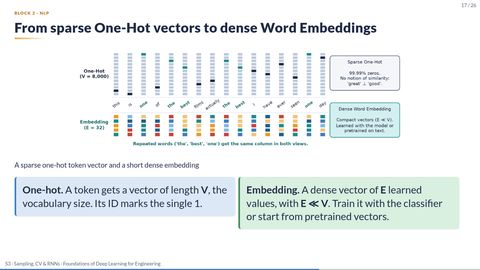 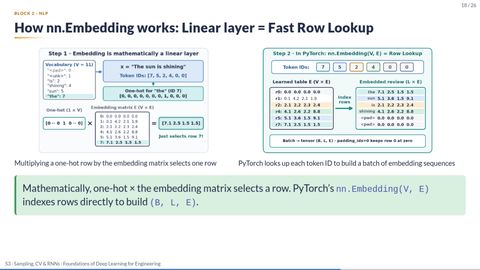

<sub>Slides 17 and 18 · dense Word Embeddings | Fast Row Lookup</sub>

Start with one short review. Split it into tokens, look up each ID and pad the sequence. The vocabulary learns from training reviews only. An unknown token gets ID 1 and padding gets ID 0.

Now take one batch. Its token IDs have shape `[batch, time]`. The embedding looks up a vector of 32 numbers for each ID, giving `[batch, time, 32]`.

In [ ]:
# ▶ S3·L2·2a
BASE_MAX_LEN = 64 if FAST else 160
BATCH_SIZE = 128 if FAST else 256

imdb_vocab = fdle.SimpleVocab(max_size=8_000).fit(train_text)
sample_review = "A moving film with quuxzvnever"
tokens = fdle.tokenize(sample_review)
sample_ids = imdb_vocab.encode(sample_review, max_len=8)
print(f"Review: {sample_review}")
print("Tokens:", tokens + ["<pad>"] * (len(sample_ids) - len(tokens)))
print("    IDs:", sample_ids)
print(f"<pad> = {imdb_vocab.pad_idx} · <unk> = {imdb_vocab.unk_idx}")

train_loader, val_loader = fdle.make_text_loaders(
    train_text, train_y, val_text, val_y, imdb_vocab,
    max_len=BASE_MAX_LEN, batch_size=BATCH_SIZE,
)
sample_x, sample_y = next(iter(train_loader))
demo_emb = nn.Embedding(len(imdb_vocab), 32, padding_idx=imdb_vocab.pad_idx)
embedded = demo_emb(sample_x)
print(f"Tokens {tuple(sample_x.shape)} → embedded {tuple(embedded.shape)}")
padding_is_zero = torch.count_nonzero(demo_emb.weight[imdb_vocab.pad_idx]).item() == 0
assert padding_is_zero, "The padding embedding should contain only zeros."
print("✅ The <pad> embedding row is all zeros.")

### ▶ L2·2b · Worked example (part 2): SimpleRNNClassifier with fdle.fit

*Slides: "Compact loop to Unrolled sequence" and "Vanishing and Exploding Gradients" (slides 19 and 20), "Gated Recurrent Unit (GRU)" and "Long Short-Term Memory (LSTM)" (slides 21 and 22).*

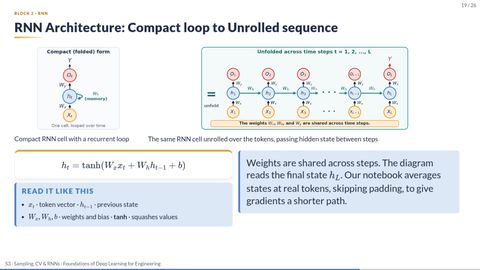 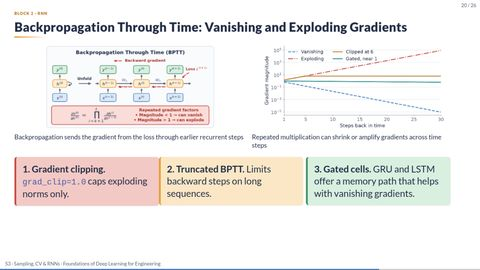 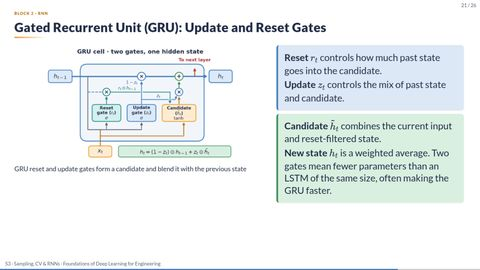 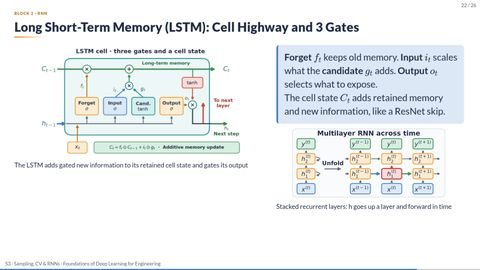

<sub>Slides 19 and 20 and 21 and 22 · Compact loop to Unrolled sequence | Vanishing and Exploding Gradients | Gated Recurrent Unit (GRU) | Long Short-Term Memory (LSTM)</sub>

The GRU reads the embedded tokens in order. Average its states over real tokens, then turn the average into two class scores. We use `grad_clip=1.0` to cap large gradients during training.

Compare the two trap sentences with BoW. Does the GRU score the more positive sentence higher? Try your own sentence with `predict_review`.

In [ ]:
# ▶ S3·L2·2b
class SimpleRNNClassifier(nn.Module):
    def __init__(self, vocab_size, pad_idx, embed_dim=32, hidden_dim=48, n_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.head = nn.Linear(hidden_dim, n_classes)

    def forward(self, tokens):
        states, _ = self.gru(self.embedding(tokens))
        mask = tokens.ne(self.embedding.padding_idx).unsqueeze(-1)
        pooled = (states * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        return self.head(pooled)


fdle.set_seed(0)
base_model = SimpleRNNClassifier(len(imdb_vocab), imdb_vocab.pad_idx)
base_history = fdle.fit(
    base_model, train_loader, val_loader, epochs=2 if FAST else 5, lr=0.003,
    grad_clip=1.0, amp=DEVICE.type == "cuda", device=DEVICE,
    name="IMDB · SimpleGRU", table=RESULTS,
)
base_acc = base_history["val_acc"][-1]
fdle.plot_history(base_history, title="IMDB · SimpleGRU")
plt.show()


@torch.inference_mode()
def predict_review(review, model=base_model, vocab=imdb_vocab, max_len=BASE_MAX_LEN):
    model.eval()
    device = next(model.parameters()).device
    tokens = torch.tensor([vocab.encode(review, max_len)], device=device)
    return model(tokens).softmax(dim=1)[0, 1].item()


bow_trap = logistic.predict_proba(bow.transform(TRAP_REVIEWS))[:, 1]
rnn_trap = [predict_review(review) for review in TRAP_REVIEWS]
print(f"{'Review':32s} {'BoW P(positive)':>16s} {'SimpleGRU P(positive)':>22s}")
for review, p_bow, p_rnn in zip(TRAP_REVIEWS, bow_trap, rnn_trap):
    print(f"{review:32s} {p_bow:16.1%} {p_rnn:22.1%}")
REFERENCE["imdb_trap"] = dict(bow=bow_trap.tolist(), cell="gru", recurrent=rnn_trap)

✍️ **If the GRU and LSTM tie on accuracy, what else would you compare?** *(double-click here and write)*

&nbsp;

### ✏️ L2·3 · Exercise 1: Build your own MyTextRNN on IMDB

*Slides: "Gated Recurrent Unit (GRU)" and "Long Short-Term Memory (LSTM)" (slides 21 and 22), and "Lab 2" (slide 24).*

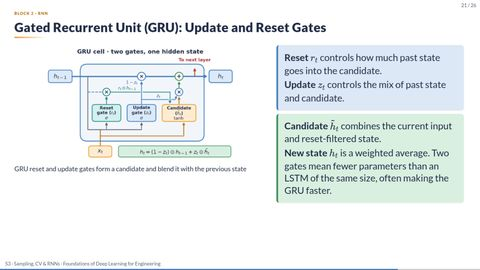 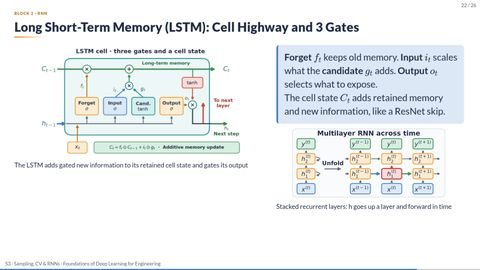 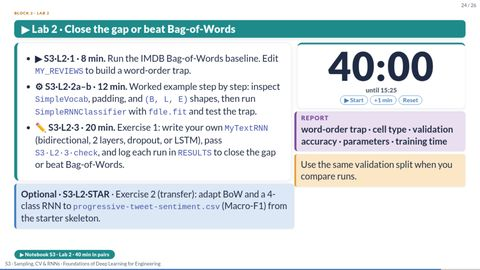

<sub>Slides 21 and 22 and 24 · Gated Recurrent Unit (GRU) | Long Short-Term Memory (LSTM) | Lab 2</sub>

Now it is your turn to write PyTorch code. Start from `SimpleRNNClassifier` and make at least **two upgrades** in `MyTextRNN(nn.Module)`.

- Make the layer bidirectional with `bidirectional=True`. The classifier input then grows to `2 * hidden_dim`.
- Stack two recurrent layers with `num_layers=2` and set `dropout`, or switch the recurrent layer to `nn.LSTM`.
- Try a larger `hidden_dim` or `max_len`. If you change the sequence length, rebuild the loaders.
- Try the last forward and backward states instead of masked mean pooling. With a bidirectional GRU and packed inputs, concatenate the top-layer states using `torch.cat((h[-2], h[-1]), dim=1)`. An LSTM returns `(h, c)`.

You have 15 minutes. Train with `fdle.fit(..., grad_clip=1.0)` and log your run in `RESULTS`. Use the same IMDB split and aim to close the gap or beat Bag-of-Words. Run the check below and inspect one validation mistake.

In [ ]:
# 🐛 S3·L2·3
class MyTextRNN(nn.Module):
    def __init__(self, vocab_size, pad_idx, n_classes=2):
        super().__init__()
        # Start with an embedding, a recurrent layer and a classifier.
        # For two directions, give the classifier 2 * hidden_dim inputs.

    def forward(self, tokens):
        # Embed the tokens, run the recurrent layer and pool the states.
        # Return one row of class scores per review.
        raise NotImplementedError("Implement the forward pass before training.")


# Instantiate your class and train it with the loaders from L2·2a.
# Pass name="IMDB · MyTextRNN" and table=RESULTS to fdle.fit to log the run.
my_model = None
my_history = None
print("✏️ Complete MyTextRNN, train it with fdle.fit(...), and rerun this cell.")

In [ ]:
# ▶ S3·L2·3·check
if (isinstance(my_model, nn.Module) and my_model is not base_model
        and isinstance(my_history, dict) and my_history.get("val_acc")):
    acc = my_history["val_acc"][-1]
    print(f"✅ Your MyTextRNN reached {acc:.1%} (BoW: {bow_acc:.1%}, SimpleGRU: {base_acc:.1%})")
else:
    print("❌ Define and train your own MyTextRNN in S3·L2·3 (try bidirectional=True, num_layers=2, or LSTM).")

### ★ L2·STAR · Exercise 2 (Transfer / Homework): 4-class tweet stance

`progressive-tweet-sentiment.csv` contains short tweets about a target. Each tweet is labeled against, for, neutral, or no clue. The classes are imbalanced, so report **macro F1** alongside accuracy and inspect the confusion matrix. Each class contributes equally to macro F1.

- **Part A.** Fit a Bag-of-Words baseline with `CountVectorizer` and `LogisticRegression` on `tweet_tr_text` and `tweet_tr_y`. You can reuse `bow_model`. Evaluate on the validation tweets and save `tweet_bow_acc` and `tweet_bow_f1`.
- **Part B.** Fit a fresh `fdle.SimpleVocab` on the training tweets and use `fdle.make_text_loaders`. Adapt `MyTextRNN` or `SimpleRNNClassifier` with `n_classes=4`. Train with `fdle.fit`, then use `fdle.evaluate` and `fdle.plot_confusion`. Save `tweet_rnn_acc` and `tweet_rnn_f1` and log both models in `RESULTS`.

About three validation tweets are NEUTRAL. How much could one mistake change the macro F1? As a follow-up, use `fdle.cross_validate` and fit the vocabulary on the training texts inside each fold.

In [ ]:
# 🐛 S3·L2·STAR
TWEET_FILE = "progressive-tweet-sentiment.csv"
TWEET_URL = ("https://raw.githubusercontent.com/santialferez/FDLE/main/"
             "S3_Sampling_RNN/data/progressive-tweet-sentiment.csv")


def load_tweets():
    for folder in (DATA, Path("notebooks/data")):
        path = folder / TWEET_FILE
        if path.is_file():
            return pd.read_csv(path, encoding="latin-1")
    response = requests.get(TWEET_URL, timeout=(5, 20))
    response.raise_for_status()
    return pd.read_csv(io.BytesIO(response.content), encoding="latin-1")


tweets = None
tweet_bow_f1 = None
tweet_rnn_f1 = None
try:
    tweets = load_tweets()
except requests.RequestException as error:
    print(f"Tweets unavailable ({error}). Put {TWEET_FILE} in ./data to try again.")
else:
    stance_column = next(c for c in tweets if c.startswith("q1_from_reading") and ":" not in c)
    tweets = tweets.dropna(subset=["tweet", "target", stance_column]).drop_duplicates(subset="tweet")
    stance = tweets[stance_column].str.split(":", n=1).str[0]
    classes = ["AGAINST", "FOR", "NEUTRAL", "NONE OF THE ABOVE"]
    class_ids = np.arange(len(classes))
    tweet_y = stance.map({name: idx for idx, name in enumerate(classes)}).to_numpy(dtype=int)
    tweet_text = (tweets["target"] + " " + tweets["tweet"]).to_numpy()
    tweet_tr_text, tweet_va_text, tweet_tr_y, tweet_va_y = train_test_split(
        tweet_text, tweet_y, test_size=0.25, random_state=0, stratify=tweet_y,
    )
    counts = np.bincount(tweet_va_y, minlength=len(classes))
    print("Validation counts:", dict(zip(classes, counts.tolist())))
    for text, label in zip(tweet_tr_text[:3], tweet_tr_y[:3]):
        print(f"{classes[label]} · {text}")

# Part A: Fit the word-count baseline and compute tweet_bow_acc and tweet_bow_f1.
# Part B: Fit the vocabulary, train a four-class model and compute tweet_rnn_acc
# and tweet_rnn_f1. Plot the confusion matrix and log both models in RESULTS.
print("✏️ Implement Part A (BoW) and Part B (4-class RNN) above and rerun!")

In [ ]:
# ▶ S3·L2·STAR·check
if all(isinstance(score, (float, np.floating)) and 0 <= score <= 1
       for score in (tweet_bow_f1, tweet_rnn_f1)):
    print(f"✅ Tweet transfer complete · Macro F1: BoW {tweet_bow_f1:.3f} vs RNN {tweet_rnn_f1:.3f}")
else:
    print("❌ Optional exercise not completed yet: compute tweet_bow_f1 (Part A) and tweet_rnn_f1 (Part B) in S3·L2·STAR.")

## Summary

*Slide: "What to remember" (slide 26).*

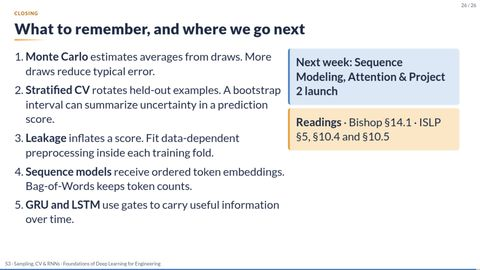

<sub>Slide 26 · What to remember</sub>

- Repeated draws let you estimate an expectation. Check how your estimate changes with the number of samples.
- Fit any data-dependent preprocessing inside each training fold. A frozen feature extractor trained on another dataset can be reused.
- Word counts discard order. A recurrent model maps an ordered sequence to hidden states, and a classifier uses those states to make a prediction.

In [ ]:
# ▶ S3·END
def save_reference():
    path = Path("s3_reference_fast.json" if FAST else "s3_reference.json")
    snapshot = dict(REFERENCE, results=RESULTS.rows)
    path.write_text(json.dumps(snapshot, indent=2) + "\n", encoding="utf-8")
    print(f"Saved {path}")


RESULTS.show()
save_reference()